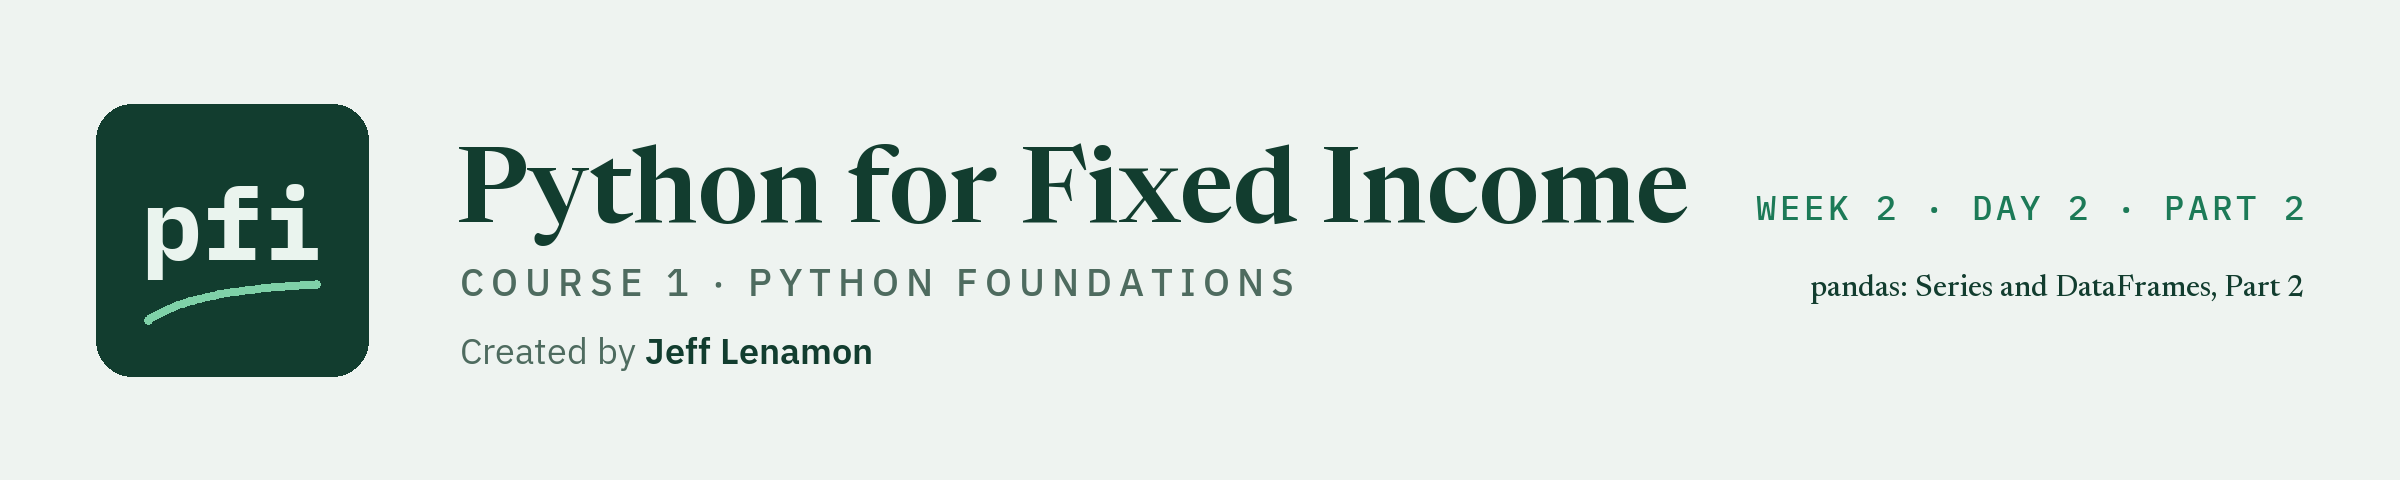

# pandas: Series and DataFrames, Part 2

Week 2, Day 2, Part 2. Summarizing, filtering, sorting, and changing a portfolio of two hundred bonds, and showing a table well.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2_part2/07_part2_pandas_series_and_dataframes.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


In Part 1 the desk built tables by hand, loaded its two hundred bonds from `holdings.csv`, and learned to reach any column and any row.

So far the table has only been read.

Now it starts answering questions.

How much is in each sector?

Which bonds are long and low in price?

Where are the widest spreads?

And what does the book look like with one bond marked lower?

The table is the same 200 bonds and 19 columns.

The issuers are invented.

**Run the cell below first.** It stores what Part 1 built, so this notebook runs on its own.

In [2]:
import os

import pandas as pd

# on your own machine the file is in the repo's data folder. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)

# the holdings with the CUSIP as the row label, from section 7.5
by_cusip = holdings.set_index('cusip')

# the four-bond table from section 7.2
desk = pd.DataFrame({
    'Ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'Coupon': [5.25, 6.125, 4.75, 7.5],
    'Maturity': [2033, 2034, 2031, 2032],
    'Price': [98.5, 103.25, 95.0, 101.0],
    'Face': [1500000, 500000, 750000, 250000],
    'Rating': ['BBB', 'BB+', 'A-', 'B+'],
})

print(holdings.shape, by_cusip.shape, desk.shape)

(200, 19) (200, 18) (4, 6)


Nothing here is new.

Part 1 built all of it, one step at a time.

## 7.6 Column Statistics

A column is a Series, so the summary methods from section 7.1 work on any column of the holdings.

Q. What is the total market value of the portfolio, and how much face does the desk hold?

In [3]:
# sum() adds up the column
print('Total market value:', holdings['market_value'].sum())
print('Total face held:', holdings['par_held'].sum())

Total market value: 490819215.0
Total face held: 489000000


490,819,215 of market value on 489,000,000 of face.

Q. What are the average and the median spread, and the lowest and highest price?

In [4]:
print('Mean OAS:', holdings['oas'].mean())
print('Median OAS:', holdings['oas'].median())
print('Lowest price:', holdings['price'].min())
print('Highest price:', holdings['price'].max())

Mean OAS: 185.75
Median OAS: 135.5
Lowest price: 62.045
Highest price: 119.131


A mean of 185.75 basis points and a median of 135.5.

The lowest price is 62.045 and the highest 119.131.

These are the figures `describe()` showed in section 7.4, one at a time.

Q. The mean spread is 185.75 and the median is 135.5. Why are they so far apart? Show the spreads of all 200 bonds.

As in the NumPy notebook, you do not need to study this chart's code today.

Run it and read the picture.

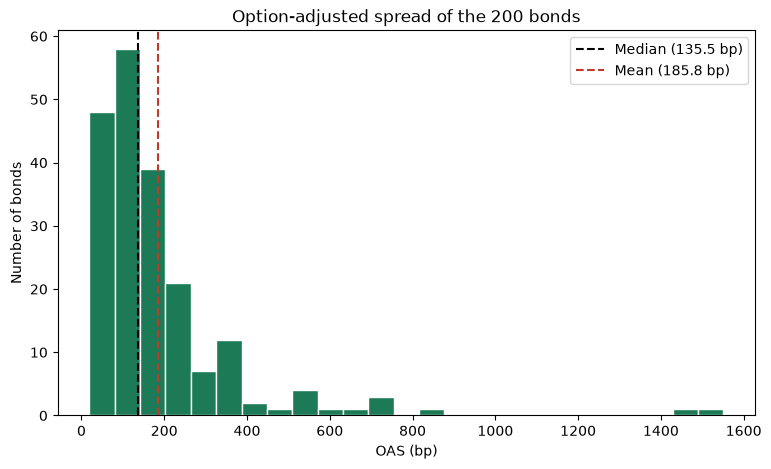

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
# hist() counts how many bonds fall in each of 25 equal-width ranges of spread
ax.hist(holdings['oas'], bins=25, color='#1c7a57', edgecolor='white')
# the dashed lines mark the median and the mean
ax.axvline(holdings['oas'].median(), color='black', linestyle='--', label=f"Median ({holdings['oas'].median():.1f} bp)")
ax.axvline(holdings['oas'].mean(), color='#c0392b', linestyle='--', label=f"Mean ({holdings['oas'].mean():.1f} bp)")
ax.set_title('Option-adjusted spread of the 200 bonds')
ax.set_xlabel('OAS (bp)')
ax.set_ylabel('Number of bonds')
ax.legend()
plt.show()

Most bonds sit at tight spreads, and a few have very wide ones.

The long tail on the right pulls the mean to the right of the median.

When a column has a tail like this, quote the median beside the mean.

The mean follows the extreme bonds, and the median describes the typical one.

Q. How many bonds does the desk hold in each sector?

In [6]:
# value_counts() counts how many times each value appears, largest first
holdings['sector'].value_counts()

sector
Financials        26
Consumer          26
Materials         26
Telecom           21
Industrials       20
Transportation    20
Health Care       20
Energy            17
Utilities         12
Technology        12
Name: count, dtype: int64

There are ten sectors.

Financials, Consumer, and Materials have 26 bonds each.

Utilities and Technology have the fewest, with 12 each.

The last line shows `int64`, the type of the counts.

Q. What share of the bonds is in each sector, as a fraction of 1?

In [7]:
# normalize=True returns each count as a share of the total
print(holdings['sector'].value_counts(normalize=True))

sector
Financials        0.130
Consumer          0.130
Materials         0.130
Telecom           0.105
Industrials       0.100
Transportation    0.100
Health Care       0.100
Energy            0.085
Utilities         0.060
Technology        0.060
Name: proportion, dtype: float64


0.13 for each of the three largest sectors, and 0.06 for Utilities and Technology: 26 of 200 and 12 of 200.

The shares add up to 1.

This is the share by count of bonds.

The share by market value is a different number.

Q. How many bonds are there at each rating?

In [8]:
holdings['rating'].value_counts()

rating
A-      28
BBB-    26
BB+     23
BBB+    21
BB      16
A+      16
BBB     15
A       12
BB-     10
B-       7
B+       6
B        5
AA-      4
CCC+     4
AA       3
AAA      2
AA+      1
CCC      1
Name: count, dtype: int64

Eighteen ratings, from AAA down to CCC.

The most common is A- with 28 bonds, then BBB- with 26 and BB+ with 23.

There are 2 bonds rated AAA and 1 rated CCC.

The rows are in order of count, not in order of credit quality.

Q. List the sectors. And does the report date differ from row to row?

In [9]:
# unique() returns each distinct value once. tolist() turns the result into a plain list.
print(holdings['sector'].unique().tolist())
print(holdings['as_of_date'].unique().tolist())

['Financials', 'Industrials', 'Transportation', 'Utilities', 'Consumer', 'Materials', 'Technology', 'Telecom', 'Health Care', 'Energy']
['2026-09-30']


The ten sector names, in the order they first appear in the file.

One date only: every row is as of 2026-09-30.

A column with a single value carries no information from row to row.

Q. How many different issuers are in the portfolio? Is every CUSIP different?

In [10]:
# nunique() is the number of distinct values
print('Tickers:', holdings['ticker'].nunique())
print('CUSIPs:', holdings['cusip'].nunique())

Tickers: 115
CUSIPs: 200


115 tickers for 200 bonds, so many issuers have more than one bond.

That is why the ticker could not serve as a row label in section 7.5.

200 CUSIPs for 200 rows.

Every label is different, which is what makes the CUSIP a safe index.

Q. Which rating appears most often?

In [11]:
# mode() is the most common value. It returns a Series, because two values can tie, so [0] takes the first.
print('Most common rating:', holdings['rating'].mode()[0])

Most common rating: A-


A- again, the rating with the most bonds.

`mode()` is the answer to 'which value occurs most often' that `value_counts()` gives as the top row.

**Excel side by side.**

<table align="left">
<tr><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>holdings['market_value'].sum()</code></td><td align="left"><code>=SUM(S2:S201)</code></td></tr>
<tr><td align="left"><code>holdings['oas'].mean()</code></td><td align="left"><code>=AVERAGE(M2:M201)</code></td></tr>
<tr><td align="left"><code>holdings['oas'].median()</code></td><td align="left"><code>=MEDIAN(M2:M201)</code></td></tr>
<tr><td align="left"><code>holdings['price'].min()</code></td><td align="left"><code>=MIN(I2:I201)</code></td></tr>
<tr><td align="left"><code>holdings['sector'].value_counts()</code></td><td align="left">a pivot table with sector in Rows and a count in Values</td></tr>
<tr><td align="left"><code>holdings['sector'].value_counts(normalize=True)</code></td><td align="left">the same pivot table, with Show Values As, % of Grand Total</td></tr>
<tr><td align="left"><code>holdings['sector'].unique()</code></td><td align="left"><code>=UNIQUE(E2:E201)</code> in current versions of Excel</td></tr>
<tr><td align="left"><code>holdings['ticker'].nunique()</code></td><td align="left"><code>=COUNTA(UNIQUE(C2:C201))</code> in current versions of Excel</td></tr>
</table>
<br clear="left">

The pandas side names the column.

The Excel side names a range, and the range has to be changed when the file grows.

## 7.7 Filtering Rows

The desk rarely wants a row by its position or its CUSIP.

It wants the rows that meet a condition: a sector, a rating, a spread above a level.

This works the way a boolean mask worked in NumPy.

Q. Which bonds are in the Energy sector?

In [12]:
# a comparison on a column returns a Series of True and False, one per row
is_energy = holdings['sector'] == 'Energy'

# rows 65 to 68, where the first Energy bonds appear
is_energy.iloc[65:69]

65    False
66    False
67     True
68     True
Name: sector, dtype: bool

False, False, then True for rows 67 and 68.

`==` asks 'is it equal to', as in week 1.

The type of the result is `bool`.

Q. Show the Energy bonds.

In [13]:
# a mask inside the square brackets keeps the rows where it is True
energy = holdings[is_energy]
energy[['ticker', 'issuer', 'rating', 'price', 'oas']].head()

,ticker,issuer,rating,price,oas
67,GALN,Galvostrin Resources,BBB+,86.621,99
68,GALN,Galvostrin Resources,BBB+,89.089,88
73,GALY,Galvolvey Resources,A+,93.393,74
82,HESR,Heskentor Resources,BBB-,112.884,155
86,HULR,Hulvimer Pipeline,BBB,93.030,110


Every row shown is an Energy issuer.

Look at the index on the left: the rows kept their original labels, so the numbers are no longer 0, 1, 2.

The filter picks rows out.

It does not renumber them.

Q. How many Energy bonds are there, and what is their total market value?

In [14]:
# the sum of a mask is a count, as in NumPy
print('Energy bonds:', is_energy.sum())
# loc[mask, column] keeps the rows that pass and one column
print('Energy market value:', holdings.loc[is_energy, 'market_value'].sum())

Energy bonds: 17
Energy market value: 38830005.0


17 bonds, with a market value of 38,830,005.

`loc` takes a mask in the row position as well as a label.

`holdings.loc[is_energy, 'market_value']` reads as: the rows where the mask is True, and the market value column.

Q. How many bonds are priced below par?

In [15]:
# the mask can be written in place
print('Bonds below par:', (holdings['price'] < 100).sum())

Bonds below par: 113


113 of the 200 bonds have a clean price below 100.

Q. Show the bonds with an OAS above 500 basis points.

In [16]:
# rows where the spread is above 500, and five columns
holdings.loc[holdings['oas'] > 500, ['ticker', 'sector', 'rating', 'price', 'oas']]

,ticker,sector,rating,price,oas
1,BEZH,Industrials,B,97.556,535
17,CLDB,Consumer,B,62.045,1446
18,CLDB,Consumer,B,95.248,520
65,FESR,Technology,CCC+,87.116,1551
66,FESR,Technology,CCC+,87.473,614
72,GALX,Materials,B-,87.457,679
110,NEVN,Utilities,B-,96.616,720
111,NEVN,Utilities,B-,94.053,719
131,PRAN,Financials,CCC+,100.010,707
132,PRAN,Financials,CCC+,89.407,871


Twelve bonds pass.

All are rated B+ or lower, and the spreads run from 520 to 1,551 basis points.

Two conditions are combined as in NumPy, with `&` and `|`.

Q. Which bonds have a duration above 10 and a price below 90?

In [17]:
# & keeps the rows where both conditions are True
long_and_low = (holdings['duration'] > 10) & (holdings['price'] < 90)
print('Count:', long_and_low.sum())
holdings.loc[long_and_low, ['ticker', 'coupon', 'maturity', 'price', 'duration']]

Count: 6


,ticker,coupon,maturity,price,duration
36,DNMR,5.250,2047-06-05,89.056,11.764
84,HLVF,7.625,2053-06-08,88.366,10.218
105,MORX,6.125,2055-12-21,85.722,12.139
117,NEVX,3.875,2048-01-06,73.873,12.898
150,SYLX,3.625,2055-09-03,76.903,16.042
184,WYXA,6.750,2056-02-23,86.884,11.558


Six bonds pass.

All mature in 2047 or later, and the prices run from 73.873 to 89.056.

Q. Which bonds have a price below 80 or an OAS above 1,000?

In [18]:
# | keeps the rows where at least one condition is True
low_or_wide = (holdings['price'] < 80) | (holdings['oas'] > 1000)
print('Count:', low_or_wide.sum())
holdings.loc[low_or_wide, ['ticker', 'rating', 'coupon', 'maturity', 'price', 'oas']]

Count: 4


,ticker,rating,coupon,maturity,price,oas
17,CLDB,B,9.500,2034-12-06,62.045,1446
65,FESR,CCC+,10.750,2028-08-08,87.116,1551
117,NEVX,BBB-,3.875,2048-01-06,73.873,153
150,SYLX,A+,3.625,2055-09-03,76.903,59


Four bonds pass.

CLDB meets both conditions, at a price of 62.045 and an OAS of 1,446.

FESR is in on its spread of 1,551 with a price of 87.116.

NEVX and SYLX are in on price alone: both mature in 2048 or later with coupons below 4 percent, and their spreads are 153 and 59.

`|` is the wider test and `&` the narrower one.

Swapping them changes the answer without causing an error, so check the count against what you expect.

The word `and` fails here with the same `ValueError` as in NumPy, this time saying 'The truth value of a Series is ambiguous'.

Q. How many bonds are rated in the single-A category, and what is their average OAS?

In [19]:
# isin() is True where the value is one of those in the list
single_a = holdings['rating'].isin(['A+', 'A', 'A-'])
print('Single-A bonds:', single_a.sum())
print('Average OAS:', round(holdings.loc[single_a, 'oas'].mean(), 2))

Single-A bonds: 56
Average OAS: 79.41


56 bonds, with an average OAS of 79.41 basis points, against 185.75 for the whole portfolio.

`isin()` saves writing three conditions joined by `|`, and it takes a list of any length.

It works the same way on a list of sectors.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Show the Energy bonds</td><td align="left"><code>holdings[holdings['sector'] == 'Energy']</code></td><td align="left">AutoFilter on the sector column</td></tr>
<tr><td align="left">Count the Energy bonds</td><td align="left"><code>(holdings['sector'] == 'Energy').sum()</code></td><td align="left"><code>=COUNTIF(E:E, "Energy")</code></td></tr>
<tr><td align="left">Market value of the Energy bonds</td><td align="left"><code>holdings.loc[is_energy, 'market_value'].sum()</code></td><td align="left"><code>=SUMIF(E:E, "Energy", S:S)</code></td></tr>
<tr><td align="left">Average OAS of one rating</td><td align="left"><code>holdings.loc[holdings['rating'] == 'A', 'oas'].mean()</code></td><td align="left"><code>=AVERAGEIF(F:F, "A", M:M)</code></td></tr>
<tr><td align="left">Two conditions at once</td><td align="left"><code>((holdings['duration'] &gt; 10) &amp; (holdings['price'] &lt; 90)).sum()</code></td><td align="left"><code>=COUNTIFS(N:N, "&gt;10", I:I, "&lt;90")</code></td></tr>
<tr><td align="left">Count the ratings in a list</td><td align="left"><code>holdings['rating'].isin(['A+', 'A', 'A-']).sum()</code></td><td align="left"><code>=SUM(COUNTIF(F:F, {"A+","A","A-"}))</code></td></tr>
</table>
<br clear="left">

An AutoFilter keeps its criteria in the column dropdowns.

The pandas line keeps them in writing, where they can be read, reviewed, and rerun.

## 7.8 Sorting

Q. Which five bonds have the widest spreads?

In [20]:
# sort_values() sorts the rows by a column. ascending=False puts the largest first.
widest = holdings.sort_values('oas', ascending=False)
widest[['ticker', 'sector', 'rating', 'price', 'oas']].head()

,ticker,sector,rating,price,oas
65,FESR,Technology,CCC+,87.116,1551
17,CLDB,Consumer,B,62.045,1446
132,PRAN,Financials,CCC+,89.407,871
110,NEVN,Utilities,B-,96.616,720
111,NEVN,Utilities,B-,94.053,719


FESR at 1,551 basis points, CLDB at 1,446, PRAN at 871, and two NEVN bonds at 720 and 719.

The index labels moved with their rows: the first row is still labelled 65, its place in the file.

`holdings` itself is not sorted.

`sort_values()` returned a new table.

Q. What are the five largest positions by market value?

In [21]:
# nlargest(n, column) is a shortcut for sort, then head
holdings.nlargest(5, 'market_value')[['ticker', 'sector', 'rating', 'par_held', 'market_value']]

,ticker,sector,rating,par_held,market_value
0,BEZE,Financials,BBB-,5000000,5435500.0
59,FESA,Technology,A+,5000000,5422700.0
103,LORN,Materials,BB,4750000,5287462.5
194,ZARL,Industrials,BB+,5000000,5253950.0
104,LORX,Energy,BBB+,5000000,5241650.0


The largest position is BEZE at 5,435,500, followed by FESA, LORN, ZARL, and LORX.

All five are above 5.2 million.

Four of them are 5,000,000 of face.

LORN is 4,750,000 of face and ranks third because its price is higher.

Market value depends on price as well as size.

Q. Which three bonds have the lowest prices?

In [22]:
# nsmallest() is the same idea from the other end
holdings.nsmallest(3, 'price')[['ticker', 'coupon', 'maturity', 'price']]

,ticker,coupon,maturity,price
17,CLDB,9.500,2034-12-06,62.045
117,NEVX,3.875,2048-01-06,73.873
150,SYLX,3.625,2055-09-03,76.903


CLDB at 62.045, then NEVX and SYLX.

One warning about sorting text.

Suppose the desk sorts by rating.

Q. Sort the holdings by rating, and list the ratings in the order they come out.

In [23]:
# sort by the rating column, then list each rating once, in sorted order
by_rating = holdings.sort_values('rating')
print(by_rating['rating'].unique().tolist())

['A', 'A+', 'A-', 'AA', 'AA+', 'AA-', 'AAA', 'B', 'B+', 'B-', 'BB', 'BB+', 'BB-', 'BBB', 'BBB+', 'BBB-', 'CCC', 'CCC+']


The order starts A, A+, A-, AA, AA+, AA-, AAA and ends CCC, CCC+.

That is alphabetical order, not credit order: AAA comes out seventh.

The rating is text, and text sorts letter by letter.

Sorting by credit quality takes a number for each rating, like the score from week 1.

**Excel side by side.** `sort_values()` is Data, Sort on one column, and `nlargest(5, 'market_value')` is that sort followed by reading off the top five rows.

`=LARGE(S2:S201, 1)` is the single largest value, and `=SMALL()` is the same from the other end.

Data, Sort changes the sheet in place. pandas hands back a sorted copy and leaves the original order alone, so there is nothing to undo.

## 7.9 Adding and Changing Data

So far we have only read the table.

Now we add to it and change it.

Q. Add a column with the annual coupon income of each position: face held times coupon, divided by 100.

In [24]:
# assigning to a column name that does not exist creates the column
holdings['coupon_income'] = holdings['par_held'] * holdings['coupon'] / 100

print('Total annual coupon income:', holdings['coupon_income'].sum())
holdings[['ticker', 'coupon', 'par_held', 'coupon_income']].head(3)

Total annual coupon income:

 28864375.0


,ticker,coupon,par_held,coupon_income
0,BEZE,7.000,5000000,350000.0
1,BEZH,8.125,250000,20312.5
2,BEZL,5.125,1500000,76875.0


The first position, 5,000,000 of a 7% bond, pays 350,000 a year.

The whole portfolio pays 28,864,375.

The right-hand side is the arithmetic from section 7.1, on two columns of 200 rows.

The left-hand side gives the result a name, and the new column goes on the right-hand end of the table.

Q. Add the weight of each position, in percent of the portfolio's market value. What are the three largest weights?

In [25]:
# each market value divided by the total, in percent
holdings['weight_pct'] = holdings['market_value'] / holdings['market_value'].sum() * 100

print('Sum of the weights:', round(holdings['weight_pct'].sum(), 6))
holdings.nlargest(3, 'weight_pct')[['ticker', 'market_value', 'weight_pct']]

Sum of the weights: 100.0


,ticker,market_value,weight_pct
0,BEZE,5435500.0,1.107434
59,FESA,5422700.0,1.104826
103,LORN,5287462.5,1.077273


The weights add up to 100, which is the check to run on any weight column.

The largest position, BEZE, is about 1.11 percent of the portfolio.

With 200 bonds, an equal split would be 0.5 percent each.

Adding a column that is calculated from other columns is safe: the source data is untouched.

Changing a value is different.

The holdings are the desk's record, so a what-if belongs in a copy.

Q. The desk wants to see the portfolio with BEZL 5.125% of 2030, CUSIP 99039NAC0, marked at 97.00. Its price in the file is 98.73.

In [26]:
# copy() makes a separate table, so the what-if cannot change the original
what_if = by_cusip.copy()

# loc[row label, column name] on the left of the equals sign sets that one value
what_if.loc['99039NAC0', 'price'] = 97.0

print('What-if price:', what_if.loc['99039NAC0', 'price'])
print('Original price:', by_cusip.loc['99039NAC0', 'price'])

What-if price: 97.0
Original price: 98.73


97.0 in the what-if table and 98.73 in the original.

`what_if = by_cusip` with no `copy()` would give the same table a second name, as with lists on Day 3 of week 1, and the new price would land on the desk's record.

Always set a value with a single `loc[row, column]`.

Code you find elsewhere may use two pairs of brackets, such as `what_if['price']['99039NAC0'] = 97.0`.

That form is unreliable: depending on the version of pandas it changes the table, or warns, or does nothing.

The price changed.

The market value column did not: it is a stored number, not a live formula.

Q. Recalculate the market value column in the what-if table. By how much does the portfolio's market value change?

In [27]:
# market value = face held times (clean price plus accrued), divided by 100
what_if['market_value'] = what_if['par_held'] * (what_if['price'] + what_if['accrued']) / 100

change = what_if['market_value'].sum() - by_cusip['market_value'].sum()
print('Change in market value:', round(change, 2))

Change in market value: -25950.0


A change of -25,950.

The position is 1,500,000 of face, and the mark is 1.73 points lower: 1,500,000 times 1.73, divided by 100.

A pandas column holds values.

When an input changes, the columns built from it have to be calculated again.

A worksheet does this for you.

In a notebook you rerun the line.

Q. In the what-if table, rename `oas` to `oas_bp` and `par_held` to `face_held`.

In [28]:
# rename() takes a dictionary of old name: new name
what_if = what_if.rename(columns={'oas': 'oas_bp', 'par_held': 'face_held'})

what_if[['ticker', 'price', 'oas_bp', 'face_held']].head(3)

,ticker,price,oas_bp,face_held
cusip,,,,
99080CAE8,BEZE,106.727,147,5000000
99049XAE2,BEZH,97.556,535,250000
99039NAC0,BEZL,97.000,153,1500000


The two columns have their new names.

`rename()` returns a new table, so we assign the result back to `what_if` to keep it.

Q. The two date columns that never change, `as_of_date` and `price_date`, are not needed in the what-if. Remove them.

**Predict 1**

The holdings file has 19 columns, and `what_if` is a copy of `by_cusip`.

The next cell prints the shape of `what_if` before and after the two columns are removed.

What are the two column counts?

> A) 19, then 17.
>
> B) 18, then 16.
>
> C) 19, then 18.

Decide, then run the cell.

In [29]:
print('Before:', what_if.shape)

# drop(columns=...) returns a table without those columns
what_if = what_if.drop(columns=['as_of_date', 'price_date'])

print('After:', what_if.shape)

Before: (200, 18)
After: (200, 16)


The answer is B: from 18 columns to 16.

The table started with 18, not 19, because the CUSIP is the index and the index is not counted as a column.

Q. The desk also wants the what-if without the BEZE 7% of 2032, CUSIP 99080CAE8. Remove that row.

In [30]:
# drop(index=...) returns a table without the row with that label
what_if = what_if.drop(index='99080CAE8')

print('Rows in the what-if:', what_if.shape[0])
print('Rows in the holdings:', holdings.shape[0])

Rows in the what-if: 199
Rows in the holdings: 200


199 rows in the what-if and 200 in the holdings.

Because the index is the CUSIP, the row is removed by naming the bond, not by counting to its position.

Nothing in this section touched `holdings.csv`.

Every change was made to tables in memory.

So far one value was set at a time.

The same `loc` form, with a mask in the row position, sets every row that passes a test.

Q. The pricing team wants to confirm the mark on every bond priced below 80. In a copy of the holdings, add a column named `price_check` that reads 'Confirm' for those bonds and 'OK' for the rest.

In [31]:
# a copy of the holdings, so the desk's record is left alone
marks = holdings.copy()

# every row starts as 'OK'
marks['price_check'] = 'OK'

# loc[mask, column] = value sets that column in the rows where the mask is True
marks.loc[marks['price'] < 80, 'price_check'] = 'Confirm'

# count the rows that were changed, then show them
confirm_count = (marks['price_check'] == 'Confirm').sum()
print(f'Rows marked Confirm: {confirm_count:,} of {marks.shape[0]:,}')
marks.loc[marks['price_check'] == 'Confirm', ['ticker', 'price', 'price_check']]

Rows marked Confirm: 3 of 200


,ticker,price,price_check
17,CLDB,62.045,Confirm
117,NEVX,73.873,Confirm
150,SYLX,76.903,Confirm


3 of the 200 rows: CLDB at 62.045, NEVX at 73.873, and SYLX at 76.903.

The other 197 still read 'OK'.

`loc[mask, column] = value` is the single `loc` from above with a mask where the row label was.

It is the reliable way to change values where a condition holds, and the right form of the two-bracket line warned against earlier.

The label is a request to check a price.

It says nothing about the bonds.

Q. The desk wants the 17 Energy bonds as a table of their own, with every price 2 points lower, as a what-if. Do the holdings change?

In [32]:
# a filtered table that is going to be changed: take a copy of it, and say so in the code
energy_what_if = holdings[is_energy].copy()

# 2 points off every price in the copy
energy_what_if['price'] = energy_what_if['price'] - 2

print(f"Average Energy price in the what-if:  {energy_what_if['price'].mean():.3f}")
print(f"Average Energy price in the holdings: {holdings.loc[is_energy, 'price'].mean():.3f}")

Average Energy price in the what-if:  95.407
Average Energy price in the holdings: 97.407


95.407 in the what-if and 97.407 in the holdings.

The desk's record did not move.

The reason for `.copy()`.

Day 3 of week 1 showed two names for one list: a change made through one name shows up under the other, and `.copy()` is the cure.

The same question comes up with a filtered table: is it a table of its own, or a window onto the holdings?

In pandas 3 a filter returns a table of its own, so the holdings would be safe even without `.copy()`.

Older versions of pandas, which Colab may run, print a `SettingWithCopyWarning` when a filtered table is changed without it.

With `.copy()` the code gives the same result in every version, and the line says in writing that a separate table is meant.

The habit: filter, then `.copy()`, before changing anything in the filtered table.

Q. Change the first bond's price in a copy of the holdings, this time by position rather than by label.

In [33]:
positional = holdings.copy()
# iloc[row position, column position] on the left of = sets one value. Row 0, column 8 is price.
positional.iloc[0, 8] = 100.0

print('Copy:    ', positional.loc[0, 'price'])
print('Original:', holdings.loc[0, 'price'])

Copy:     100.0
Original: 106.727


100.0 in the copy and 106.727 in the holdings.

Use `loc` when you know the bond, and `iloc` when you know only where it sits.

Q. Add the desk's rating scores to the four-bond table from section 7.2, as a new column made from a list.

In [34]:
desk_scores = desk.copy()
# a list as long as the table becomes a column. One value per row, in row order.
desk_scores['Score'] = [9, 11, 7, 14]
print(desk_scores[['Ticker', 'Rating', 'Score']])

  Ticker Rating  Score
0   QVNE    BBB      9
1   DNMR    BB+     11
2   PLWK     A-      7
3   HLVF     B+     14


A new column, filled from the list in order.

**Predict 2**

The next cell gives the four-bond table a list of three scores:

```
desk_scores['Score'] = [9, 11, 7]
```

What do you expect?

> A) The fourth row gets a `NaN`.
>
> B) The list starts again, so the fourth row gets a 9.
>
> C) An error.

Decide, then run the cell.

In [35]:
# three scores for four bonds
desk_scores['Score'] = [9, 11, 7]

ValueError: Length of values (3) does not match length of index (4)

The answer is C. A `ValueError`: Length of values (3) does not match length of index (4). pandas will not guess which bond is missing a score.

This is the same refusal as the NumPy shape error: the lengths must match.

Q. Older tutorials remove columns and rows with `axis`. What does that do?

In [36]:
older = desk.copy()
# axis=1 means columns. This is the same as drop(columns='Rating').
older = older.drop('Rating', axis=1)
# axis=0 means rows. This drops the row labelled 1, which is DNMR.
older = older.drop(1, axis=0)
print(older)

  Ticker  Coupon  Maturity  Price     Face
0   QVNE    5.25      2033   98.5  1500000
2   PLWK    4.75      2031   95.0   750000
3   HLVF    7.50      2032  101.0   250000


The same result as `drop(columns=...)` and `drop(index=...)`.

These are the two axes from the NumPy notebook: axis 0 is rows and axis 1 is columns.

**Predict 3**

Older tutorials also write `inplace=True`.

Here it is, with what the method hands back stored in a variable:

```
result = older.drop(columns=['Face'], inplace=True)
print('Returned:', result)
```

What will `result` hold?

> A) A new table without the Face column.
>
> B) `None`.

Decide, then run the cell.

In [37]:
# the Face column goes, with inplace=True
result = older.drop(columns=['Face'], inplace=True)
print('Returned:', result)
print('Columns now:', older.columns.tolist())

Returned: None
Columns now: ['Ticker', 'Coupon', 'Maturity', 'Price']


The answer is B. `inplace=True` changes the table where it stands: it changed `older` itself and handed back `None`, so storing its result stores nothing.

The recommendation: assign the result, `older = older.drop(...)`, and leave `inplace=True` out.

The result is a new table every time, which is what the rest of pandas does.

Q. After dropping DNMR, the index runs 0, 2, 3. How do you renumber it?

In [38]:
print(older.index.tolist())

# reset_index(drop=True) renumbers the rows from 0 and throws the old numbers away
print(older.reset_index(drop=True))

# without drop=True the old numbers are kept as a column named index
print(older.reset_index())

[0, 2, 3]
  Ticker  Coupon  Maturity  Price
0   QVNE    5.25      2033   98.5
1   PLWK    4.75      2031   95.0
2   HLVF    7.50      2032  101.0
   index Ticker  Coupon  Maturity  Price
0      0   QVNE    5.25      2033   98.5
1      2   PLWK    4.75      2031   95.0
2      3   HLVF    7.50      2032  101.0


0, 2, 3 before.

After `reset_index(drop=True)` the rows are numbered 0, 1, 2.

Without `drop=True` the old numbers become a column called `index`, which is rarely what you want.

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Add a calculated column</td><td align="left"><code>holdings['coupon_income'] = holdings['par_held'] * holdings['coupon'] / 100</code></td><td align="left"><code>=R2*G2/100</code> in a new column, filled down</td></tr>
<tr><td align="left">Weight of each position</td><td align="left"><code>holdings['market_value'] / holdings['market_value'].sum() * 100</code></td><td align="left"><code>=S2/SUM($S$2:$S$201)*100</code> filled down</td></tr>
<tr><td align="left">Work on a copy</td><td align="left"><code>by_cusip.copy()</code></td><td align="left">Move or Copy, Create a copy of the sheet</td></tr>
<tr><td align="left">Overwrite one value</td><td align="left"><code>what_if.loc['99039NAC0', 'price'] = 97.0</code></td><td align="left">type over the cell</td></tr>
<tr><td align="left">Rename a column</td><td align="left"><code>rename(columns={...})</code></td><td align="left">retype the header</td></tr>
<tr><td align="left">Remove a column or a row</td><td align="left"><code>drop(columns=...)</code>, <code>drop(index=...)</code></td><td align="left">Delete column, Delete row</td></tr>
<tr><td align="left">Change values where a condition holds</td><td align="left"><code>marks.loc[marks['price'] &lt; 80, 'price_check'] = 'Confirm'</code></td><td align="left"><code>=IF(I2&lt;80, "Confirm", "OK")</code> filled down a new column</td></tr>
<tr><td align="left">A copy of the filtered rows</td><td align="left"><code>holdings[is_energy].copy()</code></td><td align="left">AutoFilter on the sector, copy the rows shown, paste on a new sheet</td></tr>
</table>
<br clear="left">

By default, copying a filtered list in Excel copies only the rows that are shown, so the paste is a separate table of those rows.

`.copy()` after a filter is the same step.

## 7.10 Showing a Table Well

The tables so far are shown as pandas prints them: decimals that do not line up, no units, and no title.

A table that another person will read needs more. pandas can format a table for display with `.style`.

It needs the `jinja2` library, which the install cell at the top of this notebook has already added.

Excel does the same job with Format Cells, to set decimals and thousands separators, and with Conditional Formatting, to shade cells by size.

The `.style` methods have the same names for the same ideas.

Q. Show the five widest spreads with prices to two decimals, spreads in basis points, market values with commas, and a title.

In [39]:
widest5 = holdings.nlargest(5, 'oas')[['ticker', 'sector', 'rating', 'price', 'oas', 'market_value']]

# .style.format() sets how each column is displayed
# set_caption() adds a title, and hide(axis='index') takes the row numbers off
# the round brackets around the whole statement let it run over several lines
(widest5.style.format({'price': '{:.2f}', 'oas': '{:,.0f} bp', 'market_value': '{:,.0f}'})
    .set_caption('Five widest spreads')
    .hide(axis='index'))

ticker,sector,rating,price,oas,market_value
FESR,Technology,CCC+,87.12,"1,551 bp","2,216,725"
CLDB,Consumer,B,62.05,"1,446 bp","1,951,590"
PRAN,Financials,CCC+,89.41,871 bp,"3,889,685"
NEVN,Utilities,B-,96.62,720 bp,"1,214,188"
NEVN,Utilities,B-,94.05,719 bp,"4,121,438"


The same five bonds, now with prices to two decimals, spreads in basis points (1,551 bp), and market values with commas.

The title sits above.

The format codes are the ones from the f-strings of Day 1 of week 1, with curly brackets around them.

In `{:,.0f}` the `.0` means no decimals.

`.style` changes only the display.

The numbers underneath keep every digit, and `widest5` is the same table it was.

This is Format Cells in Excel: the cell still holds 106.727 when it shows 106.73.

Q. Shade the table so the widest spreads stand out, and mark the highest price.

In [40]:
top10 = holdings.nlargest(10, 'oas')[['ticker', 'rating', 'price', 'oas', 'market_value']]

(top10.style.format({'price': '{:.2f}', 'oas': '{:,.0f} bp', 'market_value': '{:,.0f}'})
    .background_gradient(subset=['oas'], cmap='Greens')
    .highlight_max(subset=['price'], color='#f4d58d')
    .set_caption('Ten widest spreads, shaded by spread')
    .hide(axis='index'))

ticker,rating,price,oas,market_value
FESR,CCC+,87.12,"1,551 bp","2,216,725"
CLDB,B,62.05,"1,446 bp","1,951,590"
PRAN,CCC+,89.41,871 bp,"3,889,685"
NEVN,B-,96.62,720 bp,"1,214,188"
NEVN,B-,94.05,719 bp,"4,121,438"
PRAN,CCC+,100.01,707 bp,"1,837,342"
GALX,B-,87.46,679 bp,"1,351,560"
FESR,CCC+,87.47,614 bp,"1,133,162"
XANL,CCC,104.98,547 bp,"3,475,160"
BEZH,B,97.56,535 bp,"253,088"


The OAS column is shaded from light to dark green as the spread grows, and the highest price in the table has a yellow cell.

`subset=` says which columns a step applies to.

`cmap` is short for colour map, and `'Greens'` is a ready-made run of greens.

`'#f4d58d'` is a colour written as a code, the way a web page writes it.

`background_gradient` is Conditional Formatting, Color Scales.

`highlight_max` is a Top 1 rule.

Q. Show market value as a bar inside each cell.

In [41]:
(top10.style.format({'price': '{:.2f}', 'oas': '{:,.0f} bp', 'market_value': '{:,.0f}'})
    .bar(subset=['market_value'], color='#8fc9ae')
    .set_caption('Ten widest spreads, with market value as a bar')
    .hide(axis='index'))

ticker,rating,price,oas,market_value
FESR,CCC+,87.12,"1,551 bp","2,216,725"
CLDB,B,62.05,"1,446 bp","1,951,590"
PRAN,CCC+,89.41,871 bp,"3,889,685"
NEVN,B-,96.62,720 bp,"1,214,188"
NEVN,B-,94.05,719 bp,"4,121,438"
PRAN,CCC+,100.01,707 bp,"1,837,342"
GALX,B-,87.46,679 bp,"1,351,560"
FESR,CCC+,87.47,614 bp,"1,133,162"
XANL,CCC,104.98,547 bp,"3,475,160"
BEZH,B,97.56,535 bp,"253,088"


A bar in each market value cell, longer for the larger position.

That is Conditional Formatting, Data Bars.

A table for another reader gets formatted numbers, a caption saying what the rows are, and shading only where it helps the eye.

**Excel side by side.**

<table align="left">
<tr><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>.style.format({'price': '{:.2f}'})</code></td><td align="left">Format Cells, Number, 2 decimal places</td></tr>
<tr><td align="left"><code>.style.format({'oas': '{:,.0f} bp'})</code></td><td align="left">Format Cells, Custom, <code>#,##0" bp"</code></td></tr>
<tr><td align="left"><code>.background_gradient(cmap='Greens')</code></td><td align="left">Conditional Formatting, Color Scales</td></tr>
<tr><td align="left"><code>.bar()</code></td><td align="left">Conditional Formatting, Data Bars</td></tr>
<tr><td align="left"><code>.highlight_max()</code></td><td align="left">Conditional Formatting, Top/Bottom Rules, Top 10 Items, with 1</td></tr>
<tr><td align="left"><code>.set_caption('...')</code></td><td align="left">a title in the row above the table</td></tr>
<tr><td align="left"><code>.hide(axis='index')</code></td><td align="left">hide the row numbers by turning off the Row and Column Headings in the View tab, or start the table in column B</td></tr>
</table>
<br clear="left">

## You Can Now

By the end of this notebook, you can:

* Total, average, and count a column, and tell a mean from a median when a column has a tail
* Read the count and the share of each group with `value_counts()`
* Filter the portfolio by sector, rating, price, spread, or duration, alone or combined, and count or total what passes
* Rank the holdings: widest spreads, largest positions
* Add a calculated column such as coupon income or portfolio weight, and run a what-if on a copy without touching the desk's record
* Change the values in every row that passes a test with `loc[mask, column] = value`, and take a `.copy()` of a filtered table before changing it
* Drop columns and rows, renumber the index, and show a table with formats, shading, and bars

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the same 200-bond holdings file, with questions the lesson did not ask.

The issuers are invented.

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports pandas, loads a fresh copy of the holdings as it is in the file, and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [42]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the holdings. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)
print(holdings.shape)

(200, 19)


### Exercise 1

Q. How many bonds does the desk hold in the Materials sector, and how much face do they add up to? Store the answers in **ex1_count** and **ex1_face**.

In [43]:
ex1_count = ...
ex1_face = ...

In [44]:
check('Exercise 1 count', ex1_count, 26)
check('Exercise 1 face', ex1_face, 70500000)

Exercise 1 count: not attempted yet
Exercise 1 face: not attempted yet


### Exercise 2

Q. How many bonds are rated BBB+ and have a duration above 7? What is the average OAS of those bonds, rounded to two decimal places? Store the answers in **ex2_count** and **ex2_avg_oas**.

In [45]:
ex2_count = ...
ex2_avg_oas = ...

In [46]:
check('Exercise 2 count', ex2_count, 12)
check('Exercise 2 average OAS', ex2_avg_oas, 114.08)

Exercise 2 count: not attempted yet
Exercise 2 average OAS: not attempted yet


### Exercise 3

Q. Use `isin()` to keep the bonds in the Health Care and Technology sectors, and count them. Among those bonds, find the three with the largest DTS and list their CUSIPs, largest first. Store the answers in **ex3_count** and, as a list, in **ex3_cusips**.

In [47]:
ex3_count = ...
ex3_cusips = ...

In [48]:
check('Exercise 3 count', ex3_count, 32)
check('Exercise 3 CUSIPs', ex3_cusips, ['99069RAD2', '99014OAC7', '99016QAE6'])

Exercise 3 count: not attempted yet
Exercise 3 CUSIPs: not attempted yet


### Exercise 4

The desk asks for two figures that are not in the file.

Q. Add a column named `current_yield`: the coupon divided by the price, in percent. Then make a table indexed by CUSIP and use `loc` to look up the current yield of the bond with CUSIP 99071TAG7, rounded to two decimal places. Store it in **ex4_current_yield**.

Q. What percent of the portfolio's market value is in the Utilities sector, rounded to two decimal places? Store it in **ex4_utilities_weight**.

In [49]:
ex4_current_yield = ...
ex4_utilities_weight = ...

In [50]:
check('Exercise 4 current yield', ex4_current_yield, 4.1)
check('Exercise 4 Utilities weight', ex4_utilities_weight, 5.91)

Exercise 4 current yield: not attempted yet
Exercise 4 Utilities weight: not attempted yet


### Exercise 5

Exercise 4 found the weight of one sector.

Tomorrow the desk asks for another sector, and next month for the same figure on a new file.

A function holds the steps once and answers every one of those.

Q. Write a function `sector_weight(table, sector)` that takes a holdings table and the name of a sector, and returns the percent of the table's market value that is in that sector, rounded to two decimal places. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`. Then call it for the Energy sector and store the answer in **ex5_energy_weight**.

In [51]:
def sector_weight(table, sector):
    """
    Take a holdings table and the name of a sector,
    and return the percent of the table's market value in that sector,
    rounded to two decimal places.
    """
    ...


ex5_energy_weight = ...

In [52]:
# the first check calls your function on the holdings
check('Exercise 5 Utilities weight', sector_weight(holdings, 'Utilities'), 5.91)
check('Exercise 5 Energy weight', ex5_energy_weight, 7.91)

Exercise 5 Utilities weight: not attempted yet
Exercise 5 Energy weight: not attempted yet


### Exercise 6

Q. What share of the 200 bonds, as a fraction of 1, is in the Utilities sector? Store it in **ex6_utilities_share**. Then take the five bonds with the widest spreads, keep only the `ticker`, `rating`, and `oas` columns, and renumber the rows from 0 with `reset_index(drop=True)`. Store the table in **ex6_widest**. Finally show that table as a styled table, with the spread formatted as `{:,.0f} bp` and a caption of your choice, and store the styled table in **ex6_styled**.

In [53]:
ex6_utilities_share = ...
ex6_widest = ...
ex6_styled = ...

In [54]:
check('Exercise 6 Utilities share', ex6_utilities_share, 0.06)
check('Exercise 6 widest tickers', ... if ex6_widest is ... else ex6_widest['ticker'].tolist(), ['FESR', 'CLDB', 'PRAN', 'NEVN', 'NEVN'])
check('Exercise 6 renumbered index', ... if ex6_widest is ... else ex6_widest.index.tolist(), [0, 1, 2, 3, 4])
check('Exercise 6 styled table', ... if ex6_styled is ... else type(ex6_styled).__name__, 'Styler')

Exercise 6 Utilities share: not attempted yet
Exercise 6 widest tickers: not attempted yet
Exercise 6 renumbered index: not attempted yet
Exercise 6 styled table: not attempted yet


### Exercise 7: AI check

You ask an AI assistant for the number of bonds that are rated BBB+ and have a duration above 7, and for the average OAS of those bonds.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What numbers do you expect? You worked both out yourself in Exercise 2. Then run the code. Does it agree with you?

In [55]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# select the BBB+ bonds with a duration above 7
ai_filter = (holdings['rating'] == 'BBB+') | (holdings['duration'] > 7)

ex7_count = ai_filter.sum()
ex7_avg_oas = round(holdings.loc[ai_filter, 'oas'].mean(), 2)

print(f'Bonds rated BBB+ with a duration above 7: {ex7_count}')
print(f'Their average OAS: {ex7_avg_oas}')

Bonds rated BBB+ with a duration above 7: 88
Their average OAS: 148.12


Q. Find the bug and fix the code in the cell above, so that **ex7_count** and **ex7_avg_oas** hold the right answers.

In [56]:
check('Exercise 7 count', ex7_count, 12)
check('Exercise 7 average OAS', ex7_avg_oas, 114.08)

Exercise 7 count: not yet. You have 88
Exercise 7 average OAS: not yet. You have 148.12


## Congratulations!

You made it through your first full day of pandas.

In Part 1 you found a bond by its CUSIP.

Now you can filter the book by sector or spread, rank it in a line of code, add to it, and put a clean table in front of someone else.

You also ran a what-if on a copy and left the desk's record untouched.

That habit is what separates a working analyst from someone who just got lucky.

Next is pandas: Combining and Loading.

One table becomes several, and you learn to join them, group them, and save the results.